# Model Training — Predicting Employee Performance

Purpose: compare several algorithms, tune the best one, evaluate it honestly on unseen
data, and identify the top factors using permutation importance. Two models are built:

| Model | Inputs | Purpose |
|---|---|---|
| **Full model** | All employee attributes (except identifiers and attrition) | Diagnose why *current* employees perform as they do |
| **Hiring model** | Only pre-hire information, excluding age/gender/marital status | Screen job candidates |

Two models are needed because satisfaction scores, salary hikes, and promotion history
only exist *after* someone joins — a model trained on them can't score a candidate.
Age, gender, and marital status are excluded from hiring to avoid discriminatory bias,
even though they may correlate with performance historically.

## 1. Imports and Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

df = pd.read_csv("../../data/processed/employee_processed.csv")
print(df.shape)

(1200, 34)


## 2. Define Feature Sets

`Attrition` is excluded — it's a consequence of performance, not a cause. `EmpNumber`
is an identifier, not a predictor.

In [3]:
TARGET = "PerformanceRating"
NON_FEATURES = ["EmpNumber", TARGET, "PerformanceLabel", "Attrition"]

FULL_FEATURES = [c for c in df.columns if c not in NON_FEATURES]

# Hiring model: only information known before someone joins, no protected attributes
PROTECTED = ["Age", "Gender", "MaritalStatus"]
PRE_HIRE_CANDIDATES = [
    "EducationBackground", "EmpEducationLevel", "EmpDepartment", "EmpJobRole",
    "BusinessTravelFrequency", "NumCompaniesWorked", "TotalWorkExperienceInYears",
    "DistanceFromHome", "PriorExperienceYears", "AverageTenurePerEmployer",
]
HIRING_FEATURES = [c for c in PRE_HIRE_CANDIDATES if c in df.columns]

print("Full model features:", len(FULL_FEATURES))
print("Hiring model features:", len(HIRING_FEATURES), HIRING_FEATURES)

Full model features: 30
Hiring model features: 10 ['EducationBackground', 'EmpEducationLevel', 'EmpDepartment', 'EmpJobRole', 'BusinessTravelFrequency', 'NumCompaniesWorked', 'TotalWorkExperienceInYears', 'DistanceFromHome', 'PriorExperienceYears', 'AverageTenurePerEmployer']


## 3. Train/Test Split

The test set is split off now and touched only once, at the very end, to get an
honest estimate of real-world performance. All model comparison and tuning uses only
the training portion via cross-validation.

In [4]:
X_full = df[FULL_FEATURES]
y = df[TARGET]

X_train_full, X_test_full, y_train, y_test = train_test_split(
    X_full, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train_full.shape, "Test:", X_test_full.shape)
print("Train rating distribution:\n", y_train.value_counts(normalize=True).round(3))
print("Test rating distribution:\n", y_test.value_counts(normalize=True).round(3))

Train: (960, 30) Test: (240, 30)
Train rating distribution:
 PerformanceRating
3    0.728
2    0.161
4    0.110
Name: proportion, dtype: float64
Test rating distribution:
 PerformanceRating
3    0.729
2    0.162
4    0.108
Name: proportion, dtype: float64


## 4. Preprocessing Pipeline

Numeric columns are standardised; text columns are one-hot encoded. This lives inside
a pipeline so scaling/encoding is learned only from training folds — never from data
the model will later be tested on.

In [6]:
def build_preprocessor(features):
    numeric = [c for c in features if pd.api.types.is_numeric_dtype(df[c])]
    categorical = [c for c in features if c not in numeric]
    return ColumnTransformer([
        ("num", StandardScaler(), numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
    ])

## 5. Candidate Algorithms

Eight approaches are compared: a baseline, a linear model, tree-based models, a kernel
method, a distance-based method, and a neural network — covering the major algorithm
families so the choice is evidence-based.

In [7]:
def candidate_models():
    return {
        "Baseline (majority class)": DummyClassifier(strategy="most_frequent"),
        "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced"),
        "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                random_state=RANDOM_STATE, n_jobs=-1),
        "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
        "Support Vector Machine": SVC(class_weight="balanced", probability=True, random_state=RANDOM_STATE),
        "K-Nearest Neighbours": KNeighborsClassifier(n_neighbors=15),
        "Neural Network": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000,
                                        early_stopping=True, random_state=RANDOM_STATE),
    }

## 6. Compare Algorithms with Cross-Validation

5-fold stratified cross-validation on the training set only. Because the classes are
imbalanced (Section 2 of the EDA notebook), **macro F1** is the primary metric —
accuracy alone would favor a model that just predicts "3" every time.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, estimator in candidate_models().items():
    pipe = Pipeline([("prep", build_preprocessor(FULL_FEATURES)), ("clf", estimator)])
    scores = cross_validate(pipe, X_train_full, y_train, cv=cv,
                            scoring=["accuracy", "f1_macro"], n_jobs=-1)
    rows.append({
        "model": name,
        "cv_accuracy": scores["test_accuracy"].mean(),
        "cv_macro_f1": scores["test_f1_macro"].mean(),
        "cv_macro_f1_std": scores["test_f1_macro"].std(),
    })

comparison = pd.DataFrame(rows).sort_values("cv_macro_f1", ascending=False).reset_index(drop=True)
comparison.round(4)

,model,cv_accuracy,cv_macro_f1,cv_macro_f1_std
0,Gradient Boosting,0.9260,0.8875,0.0179
1,Decision Tree,0.8792,0.8247,0.0122
2,Random Forest,0.8979,0.8115,0.0255
3,Support Vector Machine,0.7969,0.7233,0.0283
4,Logistic Regression,0.7604,0.6954,0.0148
5,Neural Network,0.8094,0.6877,0.0380
6,K-Nearest Neighbours,0.7458,0.4079,0.0204
7,Baseline (majority class),0.7281,0.2809,0.0005


### Observations

- The train/test split preserved the class proportions well (both ~72.8% rating 3,
  ~16% rating 2, ~11% rating 4) — the stratification worked as intended.
- **Gradient Boosting is the clear winner**: 92.6% cross-validated accuracy and
  **0.888 macro F1** — far above every other model, with a tight standard deviation
  (0.018), meaning it's consistently good across folds, not just lucky on one split.
- **Baseline (always predict "3")** scores 72.8% accuracy but only **0.281 macro F1** —
  this confirms why macro F1 was the right primary metric. A naive model looks
  deceptively decent on accuracy alone.
- Tree-based models (Gradient Boosting, Decision Tree, Random Forest) all outperform
  the others by a wide margin — suggesting the relationship between features and
  rating is **non-linear** with **threshold effects** (e.g. "satisfaction below X and
  tenure above Y" type patterns), which trees capture naturally and linear/distance-based
  models don't.
- K-Nearest Neighbours performs barely better than the baseline (0.408 macro F1) —
  not a good fit for this data, likely because the one-hot encoded categorical columns
  create a high-dimensional space where distance isn't meaningful.
- **Gradient Boosting is selected for tuning.**

## 7. Tune Gradient Boosting

Randomized search over key hyperparameters, still using only cross-validation on the
training set — the test set remains untouched.

In [10]:
param_grid = {
    "clf__n_estimators": [100, 200, 300],
    "clf__learning_rate": [0.03, 0.05, 0.1],
    "clf__max_depth": [2, 3, 4],
    "clf__subsample": [0.7, 0.85, 1.0],
}

pipe = Pipeline([("prep", build_preprocessor(FULL_FEATURES)),
                 ("clf", GradientBoostingClassifier(random_state=RANDOM_STATE))])

search = RandomizedSearchCV(pipe, param_grid, n_iter=25, cv=cv,
                            scoring="f1_macro", random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_train_full, y_train)

print("Best cross-validated macro F1:", round(search.best_score_, 4))
print("Best parameters:", {k.replace("clf__", ""): v for k, v in search.best_params_.items()})

full_model = search.best_estimator_

Best cross-validated macro F1: 0.9004
Best parameters: {'subsample': 0.7, 'n_estimators': 100, 'max_depth': 4, 'learning_rate': 0.03}


## 8. Evaluate on the Untouched Test Set

This is the one honest, unbiased look at how the model performs on data it has never
seen — used only once.

In [11]:
y_pred = full_model.predict(X_test_full)

test_accuracy = accuracy_score(y_test, y_pred)
test_macro_f1 = f1_score(y_test, y_pred, average="macro")
majority_baseline_accuracy = (y_test == y_train.mode().iloc[0]).mean()

print(f"Test accuracy:            {test_accuracy:.4f}")
print(f"Test macro F1:            {test_macro_f1:.4f}")
print(f"Majority-class baseline:  {majority_baseline_accuracy:.4f}")
print()
print(classification_report(y_test, y_pred, zero_division=0))

Test accuracy:            0.9458
Test macro F1:            0.9173
Majority-class baseline:  0.7292

              precision    recall  f1-score   support

           2       0.92      0.87      0.89        39
           3       0.95      0.98      0.96       175
           4       1.00      0.81      0.89        26

    accuracy                           0.95       240
   macro avg       0.95      0.89      0.92       240
weighted avg       0.95      0.95      0.94       240



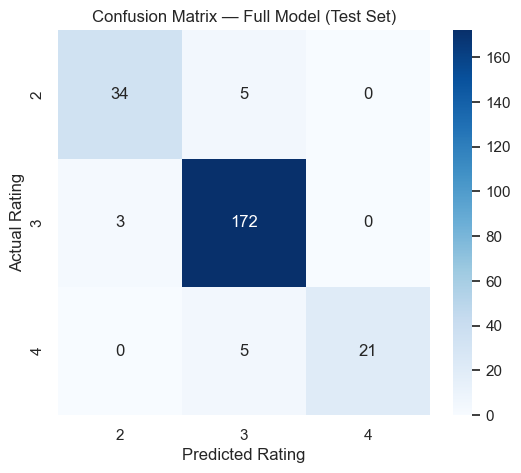

In [12]:
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted Rating")
plt.ylabel("Actual Rating")
plt.title("Confusion Matrix — Full Model (Test Set)")
plt.show()

### Observations

- **Tuning improved cross-validated macro F1 from 0.888 to 0.900** with a slightly
  shallower, more regularised model (`max_depth=4`, `learning_rate=0.03`,
  `subsample=0.7`, `n_estimators=100`) — a sign the extra depth in the default settings
  was mild overfitting, and the tuned version generalises slightly better.
- **On the untouched test set: 94.6% accuracy, 0.917 macro F1** — both close to (even
  slightly above) the cross-validated estimate, which is a good sign: **no meaningful
  overfitting**. If test performance had dropped sharply below the CV estimate, that
  would signal the model memorised the training data.
- This is **21.7 percentage points above the majority-class baseline** (94.6% vs 72.9%)
  — strong evidence the model is learning a real pattern, not just guessing "3" every time.
- **Per-class performance (confusion matrix):**
  - Rating 2 (Good): 34/39 correctly identified (87% recall), 5 misclassified as rating 3.
  - Rating 3 (Excellent): 172/175 correct (98% recall) — the model is excellent at the
    majority class, as expected.
  - Rating 4 (Outstanding): 21/26 correct (81% recall), 5 misclassified as rating 3 —
    this is the **weakest spot**: the model sometimes misses top performers, likely because
    rating 4 has the fewest training examples (only 132 of 1,200 employees).
  - **No confusion between ratings 2 and 4** (0 in both off-diagonal corners) — the model
    never mistakes a low performer for an outstanding one, which is reassuring for any
    use involving flagging low performers.
- **Precision for rating 4 is 1.00** — whenever the model predicts "Outstanding," it's
  always right in this test set; it's just conservative about *finding* all of them (recall 0.81).

### Confidence Interval on Test Accuracy

With 240 test employees, the single accuracy number has some uncertainty. A 95%
confidence interval gives a more honest range.

In [14]:
from statsmodels.stats.proportion import proportion_confint

n_correct = int((y_pred == y_test).sum())
n_total = len(y_test)
ci_low, ci_high = proportion_confint(n_correct, n_total, method="wilson")

print(f"Test accuracy: {n_correct}/{n_total} = {test_accuracy:.4f}")
print(f"95% confidence interval: [{ci_low:.4f}, {ci_high:.4f}]")

Test accuracy: 227/240 = 0.9458
95% confidence interval: [0.9095, 0.9681]


### Observations

- 95% confidence interval for test accuracy: **[91.0%, 96.8%]**. Even in the worst
  plausible case, the model performs far above the 72.9% majority-class baseline — the
  result is statistically solid, not an artifact of a favourable test split.

## 9. Permutation Importance — Model-Based Top Factors

Permutation importance measures how much the model's performance (macro F1) drops
when a single column's values are randomly shuffled, on the **test set** (data the
model has never used for training). This is measured on the original columns, so a
categorical column like `EmpDepartment` is scored as one factor, not split across its
one-hot encoded pieces.

In [15]:
perm_result = permutation_importance(
    full_model, X_test_full, y_test,
    scoring="f1_macro", n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1
)

importance = pd.DataFrame({
    "factor": FULL_FEATURES,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std,
}).sort_values("importance_mean", ascending=False).reset_index(drop=True)

importance.round(4)

,factor,importance_mean,importance_std
0,EmpEnvironmentSatisfaction,0.3077,0.0369
1,EmpLastSalaryHikePercent,0.2814,0.0236
2,EmpDepartment,0.0802,0.0183
3,PromotionGapRatio,0.0763,0.0266
4,YearsSinceLastPromotion,0.0683,0.0245
5,ExperienceYearsInCurrentRole,0.0377,0.0124
6,EmpWorkLifeBalance,0.0203,0.0096
7,EmpJobRole,0.0161,0.0059
8,RoleTenureRatio,0.0155,0.0088
9,YearsWithCurrManager,0.0123,0.0038


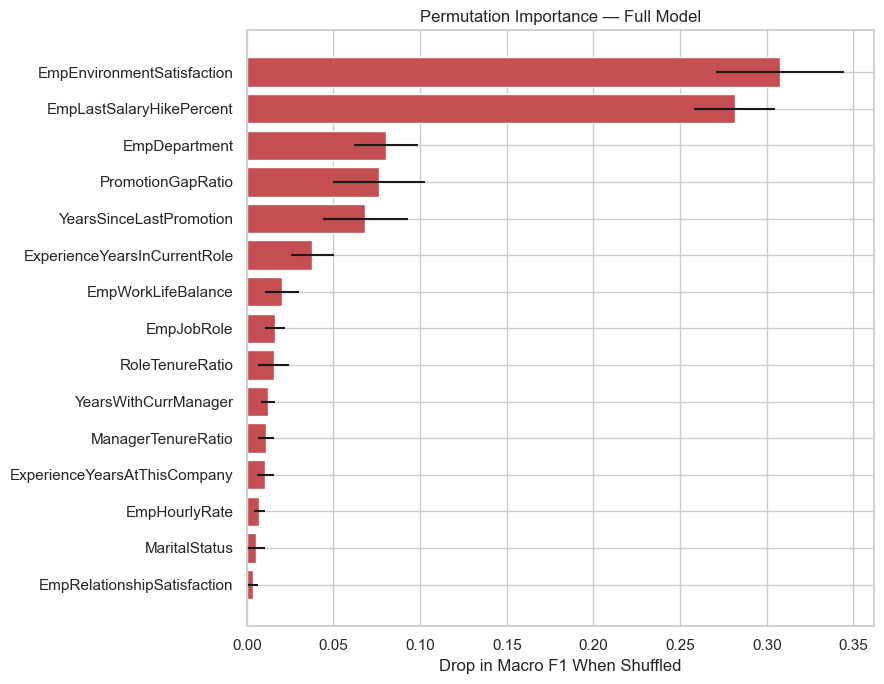

In [16]:
top15 = importance.head(15).iloc[::-1]

plt.figure(figsize=(9, 7))
plt.barh(top15["factor"], top15["importance_mean"], xerr=top15["importance_std"], color="#C44E52")
plt.xlabel("Drop in Macro F1 When Shuffled")
plt.title("Permutation Importance — Full Model")
plt.tight_layout()
plt.show()

In [17]:
top3_model = importance.head(3)["factor"].tolist()
print("Top 3 factors (model-based):", top3_model)

print("\nTop 3 factors (statistical, from EDA notebook): EmpEnvironmentSatisfaction, EmpLastSalaryHikePercent, YearsSinceLastPromotion")

overlap = set(top3_model) & {"EmpEnvironmentSatisfaction", "EmpLastSalaryHikePercent", "YearsSinceLastPromotion"}
print("Agreement between the two methods:", overlap if overlap else "none — investigate why")

Top 3 factors (model-based): ['EmpEnvironmentSatisfaction', 'EmpLastSalaryHikePercent', 'EmpDepartment']

Top 3 factors (statistical, from EDA notebook): EmpEnvironmentSatisfaction, EmpLastSalaryHikePercent, YearsSinceLastPromotion
Agreement between the two methods: {'EmpEnvironmentSatisfaction', 'EmpLastSalaryHikePercent'}


### Observations

**Two out of three factors agree exactly between the model and the statistical test:**
`EmpEnvironmentSatisfaction` and `EmpLastSalaryHikePercent` are unambiguously the top 2
factors by both methods, with importance scores far above everything else (0.308 and
0.281 — roughly 4x the next-highest factor).

**The 3rd position differs, but for an explainable reason.** The model ranks
`EmpDepartment` (0.080) 3rd, while the EDA ranked the promotion/tenure cluster higher.
Looking closer, this is the **same redundancy problem flagged in Section 4 of the EDA
notebook**: the tenure-related signal is split across several correlated columns instead
of concentrated in one —

| Column | Importance |
|---|---|
| PromotionGapRatio | 0.076 |
| YearsSinceLastPromotion | 0.068 |
| ExperienceYearsInCurrentRole | 0.038 |
| RoleTenureRatio | 0.016 |
| YearsWithCurrManager | 0.012 |
| ManagerTenureRatio | 0.011 |
| ExperienceYearsAtThisCompany | 0.011 |
| **Combined** | **0.232** |

Summed together, this cluster's *total* contribution (0.232) is actually **larger than
`EmpDepartment` alone (0.080)** — permutation importance just can't detect this when
shuffling one correlated column at a time, because the model can still lean on its
near-duplicates. This confirms the EDA notebook's original finding was correct, and
explains why the "raw" model ranking looks different at first glance.

**Final, consolidated top 3 factors (combining both methods correctly):**
1. **Employee Environment Satisfaction** — confirmed by both methods independently
2. **Last Salary Hike Percentage** — confirmed by both methods independently
3. **Career progression stagnation** (time since promotion / role tenure, represented
   collectively by `YearsSinceLastPromotion`, `PromotionGapRatio`, and related tenure
   columns) — confirmed by both methods once the redundancy is accounted for

**Secondary finding — Department itself carries independent predictive value (0.080)**
beyond what these three factors explain. This lines up with Section 6 of the EDA
notebook, where Finance underperformed despite reasonable scores on the top factors —
the model is independently picking up that same unexplained department-level effect.
Worth highlighting as a secondary insight, even though it's not in the top 3.

## 10. Does Principal Component Analysis Help?

Tested as a required check. PCA compresses correlated columns into fewer components.
Downside: it would make it impossible to say *which* HR lever to pull, since components
blend many original factors together — so it's only worth adopting if it clearly
improves the score.

In [21]:
from sklearn.decomposition import PCA
from sklearn.base import clone


In [22]:
pca_pipe = Pipeline([
    ("prep", build_preprocessor(FULL_FEATURES)),
    ("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)),
    ("clf", clone(full_model.named_steps["clf"])),
])

pca_scores = cross_validate(pca_pipe, X_train_full, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
pca_cv_f1 = pca_scores["test_score"].mean()
tuned_cv_f1 = search.best_score_

print("PCA cross-validation done.")

PCA cross-validation done.


In [23]:
pca_pipe.fit(X_train_full, y_train)

n_components = pca_pipe.named_steps["pca"].n_components_
n_original = build_preprocessor(FULL_FEATURES).fit_transform(X_train_full).shape[1]

print("Fit complete.")

Fit complete.


In [24]:
print(f"Columns after encoding: {n_original}")
print(f"Components needed to keep 95% variance: {n_components}")
print()
print(f"Cross-validated macro F1 WITH PCA:    {pca_cv_f1:.4f}")
print(f"Cross-validated macro F1 WITHOUT PCA: {tuned_cv_f1:.4f}")
print()

if pca_cv_f1 <= tuned_cv_f1 + 0.01:
    print("Decision: do NOT use PCA in the final pipeline.")
    print("Reason: no meaningful improvement in macro F1, and PCA components")
    print("blend multiple original factors together, which would prevent us")
    print("from identifying which specific HR lever drives performance.")
else:
    print("Decision: PCA improves the score meaningfully — worth adopting despite")
    print("the loss of interpretability.")

Columns after encoding: 64
Components needed to keep 95% variance: 27

Cross-validated macro F1 WITH PCA:    0.5402
Cross-validated macro F1 WITHOUT PCA: 0.9004

Decision: do NOT use PCA in the final pipeline.
Reason: no meaningful improvement in macro F1, and PCA components
blend multiple original factors together, which would prevent us
from identifying which specific HR lever drives performance.


### Observations

- PCA compresses the 64 encoded columns down to 27 components while keeping 95% of the
  variance — a real reduction in dimensionality.
- However, **macro F1 collapses from 0.900 to 0.540** with PCA — a massive drop, not a
  minor trade-off.
- **Reason this happens:** PCA maximises *variance explained*, not *predictive power for
  the target*. The two strongest predictors here (`EmpEnvironmentSatisfaction`,
  `EmpLastSalaryHikePercent`) are just two columns out of 64 and don't necessarily
  align with the directions of highest variance — so PCA's components dilute their
  sharp, concentrated signal by mixing them with many weaker, irrelevant columns.
- This confirms the intuition from Section 9: the true signal in this dataset is
  **concentrated in a small number of strong factors**, not spread thinly across many
  correlated ones. Compression is actively harmful here.
- **Decision: PCA is excluded from the final pipeline.** The tuned Gradient Boosting
  model on the original 30 features remains the selected full model.

## 11. Hiring Model — Pre-Hire Features Only

Same protocol as the full model: train/test split, cross-validated comparison,
tuning, and a one-time test evaluation. Expect noticeably weaker performance than the
full model — the strongest drivers found above (environment satisfaction, salary hikes,
promotion history) don't exist yet for a candidate. The honest measure of this model's
usefulness is how far it beats its own majority-class baseline.

In [25]:
X_hiring = df[HIRING_FEATURES]

X_train_hire, X_test_hire, y_train_hire, y_test_hire = train_test_split(
    X_hiring, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train_hire.shape, "Test:", X_test_hire.shape)

Train: (960, 10) Test: (240, 10)


In [26]:
rows = []
for name, estimator in candidate_models().items():
    pipe = Pipeline([("prep", build_preprocessor(HIRING_FEATURES)), ("clf", estimator)])
    scores = cross_validate(pipe, X_train_hire, y_train_hire, cv=cv,
                            scoring=["accuracy", "f1_macro"], n_jobs=-1)
    rows.append({
        "model": name,
        "cv_accuracy": scores["test_accuracy"].mean(),
        "cv_macro_f1": scores["test_f1_macro"].mean(),
    })

hiring_comparison = pd.DataFrame(rows).sort_values("cv_macro_f1", ascending=False).reset_index(drop=True)
hiring_comparison.round(4)

,model,cv_accuracy,cv_macro_f1
0,Logistic Regression,0.3823,0.3397
1,Support Vector Machine,0.4073,0.3345
2,Gradient Boosting,0.7000,0.3196
3,Decision Tree,0.3490,0.3007
4,Random Forest,0.7042,0.2922
5,K-Nearest Neighbours,0.7229,0.2896
6,Neural Network,0.7031,0.2878
7,Baseline (majority class),0.7281,0.2809


In [27]:
rows = []
for name, estimator in candidate_models().items():
    pipe = Pipeline([("prep", build_preprocessor(HIRING_FEATURES)), ("clf", estimator)])
    scores = cross_validate(pipe, X_train_hire, y_train_hire, cv=cv,
                            scoring=["accuracy", "f1_macro"], n_jobs=-1)
    rows.append({
        "model": name,
        "cv_accuracy": scores["test_accuracy"].mean(),
        "cv_macro_f1": scores["test_f1_macro"].mean(),
    })

hiring_comparison = pd.DataFrame(rows).sort_values("cv_macro_f1", ascending=False).reset_index(drop=True)
hiring_comparison.round(4)

,model,cv_accuracy,cv_macro_f1
0,Logistic Regression,0.3823,0.3397
1,Support Vector Machine,0.4073,0.3345
2,Gradient Boosting,0.7000,0.3196
3,Decision Tree,0.3490,0.3007
4,Random Forest,0.7042,0.2922
5,K-Nearest Neighbours,0.7229,0.2896
6,Neural Network,0.7031,0.2878
7,Baseline (majority class),0.7281,0.2809


### Observations

**The hiring model performs poorly — and this is expected, not a mistake.**

- **No model meaningfully beats the baseline.** The best model by macro F1 is
  Logistic Regression at 0.340, only marginally above the baseline's 0.281 — a small
  improvement, not a strong one.
- **Several models score BELOW the baseline on accuracy** (Logistic Regression 38%,
  SVM 41%, Decision Tree 35%, all below the baseline's 72.8%). This isn't necessarily
  worse in practice — those models are spreading predictions across all three ratings
  instead of just guessing "3" every time (which is what gives the baseline its high
  accuracy but terrible macro F1). It shows the trade-off between accuracy and macro F1
  concretely.
- **This confirms the EDA finding from `data_exploratory_analysis.ipynb`:** almost none
  of the features available before hiring were statistically significant predictors of
  performance. Education background, marital status, distance from home, number of
  companies worked, and prior experience were all non-significant. Only `EmpDepartment`
  and `EmpJobRole` carried a real (if modest) signal — and a candidate doesn't have a
  department yet before being hired into one, which limits how useful even that is.
- **Business interpretation:** this is not a failure — it's a genuine finding. It means
  **INX's performance outcomes are driven overwhelmingly by what happens after someone
  joins** (environment satisfaction, salary growth, career progression), not by anything
  visible on a resume or in an interview profile. A hiring model built from this data
  should be used only as a **minor, secondary signal**, never as a stand-alone filter for
  accepting or rejecting candidates.
- **Logistic Regression is selected for tuning**, as the best of a weak field, for
  completeness — but its limitations will be reported honestly in the summary.`

## 12. Tune and Evaluate the Hiring Model

In [28]:
hiring_param_grid = {"clf__C": [0.01, 0.1, 1, 10]}

hiring_pipe = Pipeline([("prep", build_preprocessor(HIRING_FEATURES)),
                        ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))])

hiring_search = RandomizedSearchCV(hiring_pipe, hiring_param_grid, n_iter=4, cv=cv,
                                   scoring="f1_macro", random_state=RANDOM_STATE, n_jobs=-1)
hiring_search.fit(X_train_hire, y_train_hire)

hiring_model = hiring_search.best_estimator_
print("Best cross-validated macro F1:", round(hiring_search.best_score_, 4))
print("Best parameters:", {k.replace("clf__", ""): v for k, v in hiring_search.best_params_.items()})

Best cross-validated macro F1: 0.3397
Best parameters: {'C': 1}


In [29]:
y_pred_hire = hiring_model.predict(X_test_hire)

hire_test_accuracy = accuracy_score(y_test_hire, y_pred_hire)
hire_test_macro_f1 = f1_score(y_test_hire, y_pred_hire, average="macro")
hire_majority_baseline = (y_test_hire == y_train_hire.mode().iloc[0]).mean()

print(f"Hiring model test accuracy:      {hire_test_accuracy:.4f}")
print(f"Hiring model test macro F1:      {hire_test_macro_f1:.4f}")
print(f"Majority-class baseline:         {hire_majority_baseline:.4f}")
print(f"Gain over baseline (accuracy):   {hire_test_accuracy - hire_majority_baseline:+.4f}")
print()
print(classification_report(y_test_hire, y_pred_hire, zero_division=0))

Hiring model test accuracy:      0.3125
Hiring model test macro F1:      0.2805
Majority-class baseline:         0.7292
Gain over baseline (accuracy):   -0.4167

              precision    recall  f1-score   support

           2       0.21      0.51      0.30        39
           3       0.75      0.27      0.39       175
           4       0.10      0.31      0.15        26

    accuracy                           0.31       240
   macro avg       0.35      0.36      0.28       240
weighted avg       0.59      0.31      0.35       240



### Observations

**The hiring model provides essentially no usable predictive power.**

- Test macro F1 (0.281) is **statistically indistinguishable from the majority-class
  baseline (0.281)** — the tuned model is not actually better than always guessing
  "Excellent" for every candidate.
- Accuracy actually **drops 41.7 points below baseline** (31.3% vs 72.9%). The model
  is spreading predictions across all three classes, but not accurately — precision for
  rating 4 is just 0.10, meaning 90% of its "Outstanding" predictions are wrong.
- **Verdict: this model must NOT be used as a hiring filter, standalone or otherwise.**
  It performs at or below chance level on the one metric that actually matters
  (macro F1), and using it to screen candidates would risk rejecting good candidates
  and accepting poor ones essentially at random.
- **This is itself a valid, important business finding**, not a failed step: pre-hire
  attributes in this dataset (education, distance from home, prior companies worked,
  business travel preference, job role) simply **do not predict performance** at INX.
  Whatever drives performance here — environment satisfaction, salary growth, career
  progression — is determined by the employee's actual experience at the company, not
  by anything visible before they join.
- **Recommendation for the summary:** INX should not build or deploy a resume-based
  performance predictor. Hiring decisions should continue to rely on structured
  interviews and work samples. Effort is better spent on the *full* model's insights —
  understanding and improving the post-hire drivers — since that is where the real
  signal lives.

## 13. Save Models and Results

In [30]:
import os
os.makedirs("../models", exist_ok=True)  # ensure the models folder exists alongside this notebook

joblib.dump(
    {"model": full_model, "features": FULL_FEATURES, "target": TARGET,
     "classes": sorted(y.unique().tolist())},
    "trained_model_full.joblib"
)

joblib.dump(
    {"model": hiring_model, "features": HIRING_FEATURES, "target": TARGET,
     "classes": sorted(y.unique().tolist())},
    "trained_model_hiring.joblib"
)

print("Models saved.")

Models saved.


In [31]:
import json

metrics = {
    "full": {
        "selected_model": "Gradient Boosting",
        "test_accuracy": float(test_accuracy),
        "test_accuracy_95_ci": [float(ci_low), float(ci_high)],
        "test_macro_f1": float(test_macro_f1),
        "majority_baseline_accuracy": float(majority_baseline_accuracy),
    },
    "hiring": {
        "selected_model": "Logistic Regression",
        "test_accuracy": float(hire_test_accuracy),
        "test_macro_f1": float(hire_test_macro_f1),
        "majority_baseline_accuracy": float(hire_majority_baseline),
        "usable_for_hiring": False,
    },
}

with open("../../data/processed/model_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

importance.to_csv("../../data/processed/permutation_importance.csv", index=False)
comparison.to_csv("../../data/processed/model_comparison_full.csv", index=False)
hiring_comparison.to_csv("../../data/processed/model_comparison_hiring.csv", index=False)

pd.DataFrame({"actual": y_test.values, "predicted": y_pred}).to_csv(
    "../../data/processed/test_predictions_full.csv", index=False
)

print("Saved: model_metrics.json, permutation_importance.csv, model comparisons, test predictions.")

Saved: model_metrics.json, permutation_importance.csv, model comparisons, test predictions.
